## The environment

`probatum.env` steps many accounts at a venue on a Data's bars together in Rust, as one
Gymnasium vector environment. Each account is a backtest's, with the same fills, costs,
funding and liquidation, and each environment draws its episodes from a stream of its own.
What an agent sees, what it can do and what it is paid, then four thousand accounts acting
at random, on Bitcoin's hourly perpetual at Binance from January 2024 to June 2025.

In [1]:
import os
import pathlib
import time

import exchange_router
import matplotlib.pyplot
import numpy
import pandas
import probatum

matplotlib.pyplot.style.use(style="../oceano.mplstyle")

print(f"probatum {probatum.__version__}, exchange-router {exchange_router.__version__}")

probatum 2.0.0, exchange-router 3.0.1


### The bars

Binance's hourly perpetuals with their funding, fetched once into `bars/`, which
`binance_perp` charges; Bitcoin's up to July 2025, the bars the agents in this folder
train on.

In [2]:
PATH = pathlib.Path("../bars/binance-linear-btcusdt-ethusdt-1h-2024-2025")

if PATH.exists():
    perp = probatum.Data.load(path=PATH)
else:
    with exchange_router.Router.local(exchanges=["binance"]) as router:
        perp = probatum.Data.from_router(router, exchange="binance", market="linear",
                                         interval="1h", symbols=["BTCUSDT", "ETHUSDT"],
                                         start="2024-01-01", end="2025-12-31", funding=True)
    perp.save(path=PATH)

train, test = perp["BTCUSDT"].split(when="2025-07-01")

train

Data(BTCUSDT, 1h, 13128 bars from 2024-01-01 00:00 to 2025-06-30 23:00)

### Eight accounts

With no features the market block is the candles: 64 bars of five values. Then four values
for the instrument and four for the account, 328 in all. An action is a target weight of
the account, from fully short to fully long.

In [3]:
env = probatum.env(train, venue="binance_perp", window=64, num_envs=8, seed=0)

print(env.single_observation_space)
print(env.single_action_space)

env.describe()

Box(-inf, inf, (328,), float32)
Box(-1.0, 1.0, (1,), float32)


,name,value,source,grade,direction,cost
0,balance,"10,000 USDT",plain,venue,None,NaN
1,fees,"maker 0.02%, taker 0.05%","binance_perp, taken 2026-10-16",venue,None,NaN
2,leverage,each instrument's tier table,"binance_perp, taken 2026-10-16",venue,None,NaN
3,maintenance,each instrument's tier table,"binance_perp, taken 2026-10-16",venue,None,NaN
4,liquidation,by takeover,"binance_perp, taken 2026-10-16",venue,None,NaN
5,liquidation fee,"unused, as maintenance is kept","binance_perp, taken 2026-10-16",venue,None,NaN
6,max open orders,8 an instrument,plain,simplified,pessimistic,NaN
7,limit fills,"through, half a step past the limit","binance_perp, taken 2026-10-16",simplified,either,NaN
8,window,24 bars,plain,simplified,either,NaN
9,liquidity,10% of the trailing volume a bar,"binance_perp, a starting calibration",simplified,either,NaN


### The observation

The market block holds each bar's open, high, low and close over the last close, and its
volume over the window's mean; the account block's names are in the agent spec. Every value
over equity is 0.0 where equity is gone, so no cell is NaN.

In [4]:
obs, info = env.reset(seed=0)
names     = env.agent_spec["observation"]["account"]

print(f"{obs.shape[0]} environments of {obs.shape[1]} values, starting on rows "
      f"{info['start']}")
print(pandas.DataFrame(obs[0, :64 * 5].reshape(64, 5)[-3:],
                       columns=["open", "high", "low", "close", "volume"]).round(decimals=4))

pandas.Series(obs[0, 64 * 5:], index=names).round(decimals=4)

8 environments of 328 values, starting on rows [ 5947  1700 13058 11491  5015  5998 13007  7350]
     open    high     low   close  volume
0  1.0059  1.0072  0.9960  0.9970  1.3272
1  0.9970  0.9991  0.9929  0.9936  0.6976
2  0.9936  1.0019  0.9932  1.0000  0.6768


weight            0.0
upnl              0.0
entry_distance    0.0
shown             1.0
log_return        0.0
leverage          0.0
margin_ratio      0.0
cash_weight       1.0
dtype: float32

### A step

Each environment's action is decided at its close and filled at the next open, and the
reward is the step's log return of equity. Here eight weights from fully short to fully
long, and what came back.

In [5]:
actions = numpy.linspace(start=-1.0, stop=1.0, num=8, dtype=numpy.float32)[:, None]

obs, reward, terminated, truncated, info = env.step(actions)

pandas.DataFrame({"action": actions[:, 0], "weight after": obs[:, 64 * 5],
                  "reward": reward, "terminated": terminated, "truncated": truncated,
                  "episode": info["episode"], "step": info["step"], "start": info["start"]})

,action,weight after,reward,terminated,truncated,episode,step,start
0,-1.000000,-0.998418,-0.000470,False,False,0,1,5947
1,-0.714286,-0.714603,-0.004446,False,False,0,1,1700
2,-0.428571,-0.429422,-0.001002,False,False,0,1,13058
3,-0.142857,-0.140417,-0.000304,False,False,0,1,11491
4,0.142857,0.142648,0.000027,False,False,0,1,5015
5,0.428571,0.425076,0.002240,False,False,0,1,5998
6,0.714286,0.708329,-0.000499,False,False,0,1,13007
7,1.000000,0.998185,0.000143,False,False,0,1,7350


### Episodes and autoreset

An episode is cut after `episode_length` steps, or ends at a liquidation. Under the default
autoreset the step after an episode ends starts the next one, ignores its action, and
returns its first observation with a reward of 0.0.

In [6]:
short = probatum.env(train, venue="binance_perp", window=64, num_envs=2, episode_length=24,
                     seed=1)
short.reset(seed=1)

rows = []
for _ in range(27):
    _, reward, terminated, truncated, info = short.step(
        numpy.full(shape=(2, 1), fill_value=0.5, dtype=numpy.float32))
    rows.append({"episode": info["episode"][0], "step": info["step"][0],
                 "start": info["start"][0], "reward": reward[0],
                 "truncated": truncated[0]})

pandas.DataFrame(rows).iloc[21:]

,episode,step,start,reward,truncated
21,0,22,4012,-0.000956,False
22,0,23,4012,-0.000933,False
23,0,24,4012,0.001699,True
24,1,0,5402,0.000000,False
25,1,1,5402,-0.003972,False
26,1,2,5402,0.001534,False


### Four thousand accounts at random

4,096 accounts, each in episodes of 30 days drawn from its own stream, taking a weight drawn
at random every hour. Every episode's return as it ends, and how many steps went through on
this machine.

1,198,145 environment steps a second on 28 CPUs, 4,098 episodes ended


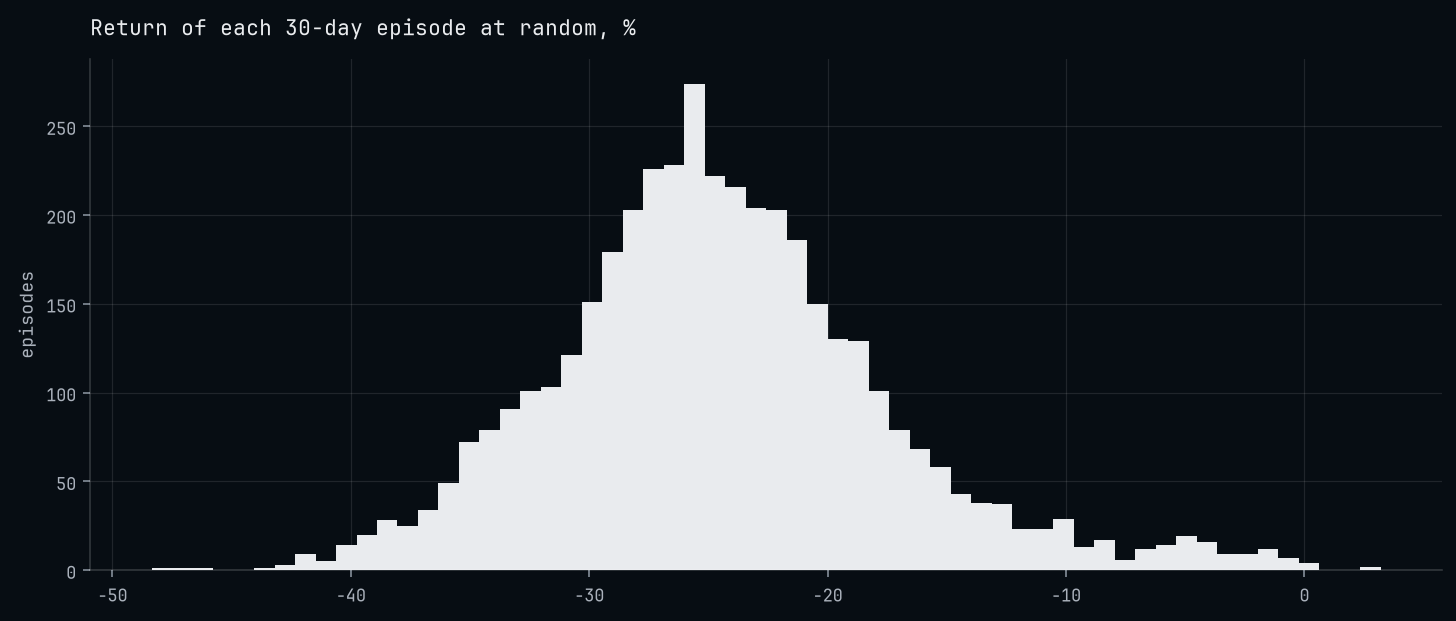

In [7]:
crowd = probatum.env(train, venue="binance_perp", window=64, num_envs=4_096,
                     episode_length=24 * 30, seed=2)
obs, _ = crowd.reset(seed=2)

draws   = numpy.random.default_rng(seed=2)
growth  = numpy.zeros(shape=crowd.num_envs)
endings = []

started = time.perf_counter()
for _ in range(24 * 30 + 1):
    obs, reward, terminated, truncated, _ = crowd.step(
        draws.uniform(low=-1.0, high=1.0, size=(crowd.num_envs, 1)).astype(numpy.float32))
    growth += reward
    ended   = terminated | truncated
    endings.extend(growth[ended])
    growth[ended] = 0.0
elapsed = time.perf_counter() - started

print(f"{crowd.num_envs * (24 * 30 + 1) / elapsed:,.0f} environment steps a second on "
      f"{os.cpu_count()} CPUs, {len(endings):,} episodes ended")

axes = pandas.Series(numpy.expm1(endings) * 100).plot(
    kind="hist", bins=60, title="Return of each 30-day episode at random, %")
axes.set_ylabel(ylabel="episodes")
matplotlib.pyplot.show()